## Load data

In [4]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

df = pd.read_csv("C:/Users/hp/predictive-maintenance-diagnosis/apps/data/processed/mafaulda_features_final.csv")  # or whatever your saved EDA output was named
feature_cols = [c for c in df.columns if c != 'fault_type']

X = df[feature_cols]
y = df['fault_type']

print(X.shape, y.shape)

(244000, 73) (244000,)


## split data

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (195200, 73) Test: (48800, 73)


## Scale

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # transform only, never fit on test

ValueError: could not convert string to float: 'C:\\Users\\hp\\predictive-maintenance-diagnosis\\data\\raw\\MAFAULDA\\vertical-misalignment\\vertical-misalignment\\1.27mm\\48.9472.csv'

## Encode labels + compute class weights

In [ ]:
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

classes = np.unique(y_train_encoded)
class_weights = compute_class_weight('balanced', classes=classes, y=y_train_encoded)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

print(dict(zip(le.classes_, class_weights)))

{'horizontal_misalignment': 1.6506041850869437, 'imbalance': 0.9764673907469513, 'normal': 6.636588596124355, 'overhang_bearing': 0.6338486222346496, 'underhang_bearing': 0.5827319855798951, 'vertical_misalignment': 1.0803065890549295}


## Dataset + DataLoader

In [ ]:
class FaultDataset(Dataset) :
    def __init__(self, X, y) :
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self) :
        return len(self.y)
    def __getitem__(self, idx) :
        return self.X[idx], self.y[idx]
    

train_dataset = FaultDataset(X_train_scaled, y_train_encoded)
test_dataset = FaultDataset(X_test_scaled, y_test_encoded)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

## Model architecture

In [ ]:
class FaultDiagnosicNet(nn.Module) : 
    def __init__(self, input_size, num_classes, dropout_rate=0.3) :
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, num_classes) 
        )
    
    def forward(self, x) :
        return self.network(x)
    
input_size = X_train_scaled.shape[1]
num_classes = len(le.classes_)

model = FaultDiagnosicNet(input_size, num_classes)
print(model)

FaultDiagnosicNet(
  (network): Sequential(
    (0): Linear(in_features=72, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): ReLU()
    (10): Linear(in_features=16, out_features=6, bias=True)
  )
)


## Training loop

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
weights_tensor = weights_tensor.to(device)
criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
n_epochs = 30
train_losses, val_losses = [], []

for epoch in range(n_epochs) :
    model.train()
    running_loss = 0.0
    for x_batch, y_batch in train_loader :
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(x_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x_batch.size(0)
    train_loss = running_loss / len(train_dataset)
    train_losses.append(train_loss)
    
    model.eval()
    val_running_loss = 0.0
    with torch.no_grad():
        for x_batch, y_batch in test_loader :
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            outputs = model(x_batch)
            loss = criterion(outputs, y_batch)
            val_running_loss += loss.item() * x_batch.size(0)
    val_loss = val_running_loss / len(test_dataset)
    val_losses.append(val_loss)
    
    print(f"Epoch {epoch+1}/{n_epochs} - train_loss: {train_loss:.4G} - val_loss: {val_loss:.4F}")
            
    
    
        

Rpoch 1/30 - train_loss: 0.4289 - val_loss: 0.1954
Rpoch 2/30 - train_loss: 0.3275 - val_loss: 0.1332
Rpoch 3/30 - train_loss: 0.2778 - val_loss: 0.1195
Rpoch 4/30 - train_loss: 0.246 - val_loss: 0.0960
Rpoch 5/30 - train_loss: 0.2328 - val_loss: 0.0890
Rpoch 6/30 - train_loss: 0.216 - val_loss: 0.0871
Rpoch 7/30 - train_loss: 0.2095 - val_loss: 0.0862
Rpoch 8/30 - train_loss: 0.2029 - val_loss: 0.0887
Rpoch 9/30 - train_loss: 0.1965 - val_loss: 0.0778
Rpoch 10/30 - train_loss: 0.1918 - val_loss: 0.0824
Rpoch 11/30 - train_loss: 0.1863 - val_loss: 0.0644
Rpoch 12/30 - train_loss: 0.1814 - val_loss: 0.0701
Rpoch 13/30 - train_loss: 0.1765 - val_loss: 0.0638
Rpoch 14/30 - train_loss: 0.177 - val_loss: 0.0635
Rpoch 15/30 - train_loss: 0.1704 - val_loss: 0.0669
Rpoch 16/30 - train_loss: 0.1706 - val_loss: 0.0591
Rpoch 17/30 - train_loss: 0.1648 - val_loss: 0.0687
Rpoch 18/30 - train_loss: 0.1653 - val_loss: 0.0672
Rpoch 19/30 - train_loss: 0.1645 - val_loss: 0.0673
Rpoch 20/30 - train_loss

## Plot loss curves

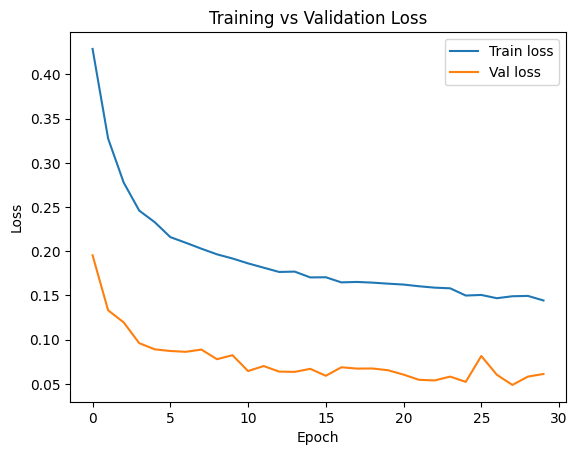

In [ ]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label='Train loss')
plt.plot(val_losses, label='Val loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training vs Validation Loss')
plt.show()